In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import IMAGE_DIR, METADATA_PATH, GROUND_TRUTH_PATH

np.set_printoptions(precision=3, suppress=True)

print("Project:", PROJECT_ROOT)
print("Images:", IMAGE_DIR)

Project: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project
Images: C:\Users\Kinjal Chatterjee\Downloads\MILK10k\images


In [8]:
metadata = pd.read_csv(METADATA_PATH)
ground_truth = pd.read_csv(GROUND_TRUTH_PATH)

label_columns = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

ground_truth["label"] = ground_truth[label_columns].idxmax(axis=1)

# Choose one lesion from each class
benign_lesion_id = ground_truth.loc[
    ground_truth["label"] == "NV", "lesion_id"
].iloc[0]

malignant_lesion_id = ground_truth.loc[
    ground_truth["label"] == "MEL", "lesion_id"
].iloc[0]

# Get the corresponding dermoscopic image IDs
def get_dermoscopic_id(lesion_id):
    return metadata.loc[
        (metadata["lesion_id"] == lesion_id) &
        (metadata["image_type"] == "dermoscopic"),
        "isic_id"
    ].iloc[0]

benign_image_id = get_dermoscopic_id(benign_lesion_id)
malignant_image_id = get_dermoscopic_id(malignant_lesion_id)

print("Benign NV:", benign_image_id)
print("Malignant MEL:", malignant_image_id)

Benign NV: ISIC_5916190
Malignant MEL: ISIC_2641217


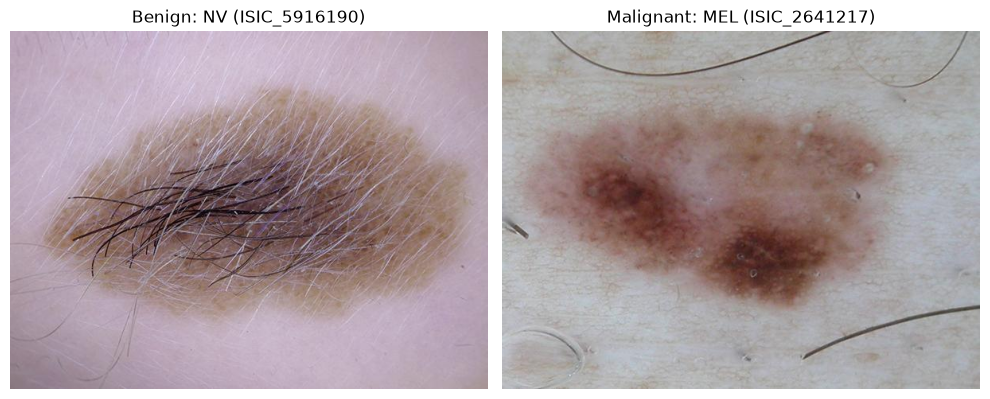

Benign array shape: (450, 600, 3)
Malignant array shape: (450, 600, 3)


In [9]:
benign_image = np.array(
    Image.open(IMAGE_DIR / f"{benign_image_id}.jpg").convert("RGB")
)

malignant_image = np.array(
    Image.open(IMAGE_DIR / f"{malignant_image_id}.jpg").convert("RGB")
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(benign_image)
axes[0].set_title(f"Benign: NV ({benign_image_id})")
axes[0].axis("off")

axes[1].imshow(malignant_image)
axes[1].set_title(f"Malignant: MEL ({malignant_image_id})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Benign array shape:", benign_image.shape)
print("Malignant array shape:", malignant_image.shape)

In [10]:
def calculate_features(rgb):
    gray = rgb.mean(axis=2)

    # Intensity histogram: 4 bins
    histogram, _ = np.histogram(
        gray, bins=4, range=(0, 256)
    )
    histogram_proportions = histogram / gray.size

    # Intensity statistics
    mean_intensity = gray.mean()
    std_intensity = gray.std()
    std_from_moments = np.sqrt(
        (gray ** 2).mean() - gray.mean() ** 2
    )

    # Texture: number of horizontal neighboring-pixel changes
    neighbor_changes = (gray[:, 1:] != gray[:, :-1]).sum()

    # Edge density: mean Sobel magnitude
    gx = ndimage.sobel(gray, axis=1)
    gy = ndimage.sobel(gray, axis=0)
    magnitude = np.hypot(gx, gy)
    edge_density = magnitude.mean()

    # Roughness: mean local variance in 9x9 windows
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray ** 2, size=9)
    roughness = np.maximum(
        local_sq_mean - local_mean ** 2, 0
    ).mean()

    # Sharpness: variance of the Laplacian
    laplacian_variance = ndimage.laplace(gray).var()

    features = {
        "Histogram bin 1 proportion": histogram_proportions[0],
        "Histogram bin 2 proportion": histogram_proportions[1],
        "Histogram bin 3 proportion": histogram_proportions[2],
        "Histogram bin 4 proportion": histogram_proportions[3],
        "Mean intensity": mean_intensity,
        "Standard deviation": std_intensity,
        "Std from moments": std_from_moments,
        "Horizontal neighbor changes": neighbor_changes,
        "Edge density (Sobel)": edge_density,
        "Roughness (local variance)": roughness,
        "Sharpness (Laplacian variance)": laplacian_variance,
    }

    return features


benign_features = calculate_features(benign_image)
malignant_features = calculate_features(malignant_image)

feature_table = pd.DataFrame({
    "Benign NV": benign_features,
    "Malignant MEL": malignant_features,
})

display(feature_table.round(3))

,Benign NV,Malignant MEL
Histogram bin 1 proportion,0.020,0.023
Histogram bin 2 proportion,0.180,0.205
Histogram bin 3 proportion,0.650,0.757
Histogram bin 4 proportion,0.149,0.015
Mean intensity,158.303,152.404
Standard deviation,37.155,32.796
Std from moments,37.155,32.796
Horizontal neighbor changes,226839.000,228433.000
Edge density (Sobel),41.655,25.664
Roughness (local variance),150.056,63.651


In [11]:
feature_table = pd.DataFrame({
    "Benign NV": benign_features,
    "Malignant MEL": malignant_features,
})

print("Number of features:", len(benign_features))
print("Benign vector length:", len(benign_features))
print("Malignant vector length:", len(malignant_features))

display(feature_table.round(4))

Number of features: 11
Benign vector length: 11
Malignant vector length: 11


,Benign NV,Malignant MEL
Histogram bin 1 proportion,0.0203,0.0227
Histogram bin 2 proportion,0.1805,0.2054
Histogram bin 3 proportion,0.6503,0.7572
Histogram bin 4 proportion,0.1489,0.0146
Mean intensity,158.3030,152.4044
Standard deviation,37.1552,32.7958
Std from moments,37.1552,32.7958
Horizontal neighbor changes,226839.0000,228433.0000
Edge density (Sobel),41.6547,25.6641
Roughness (local variance),150.0555,63.6515


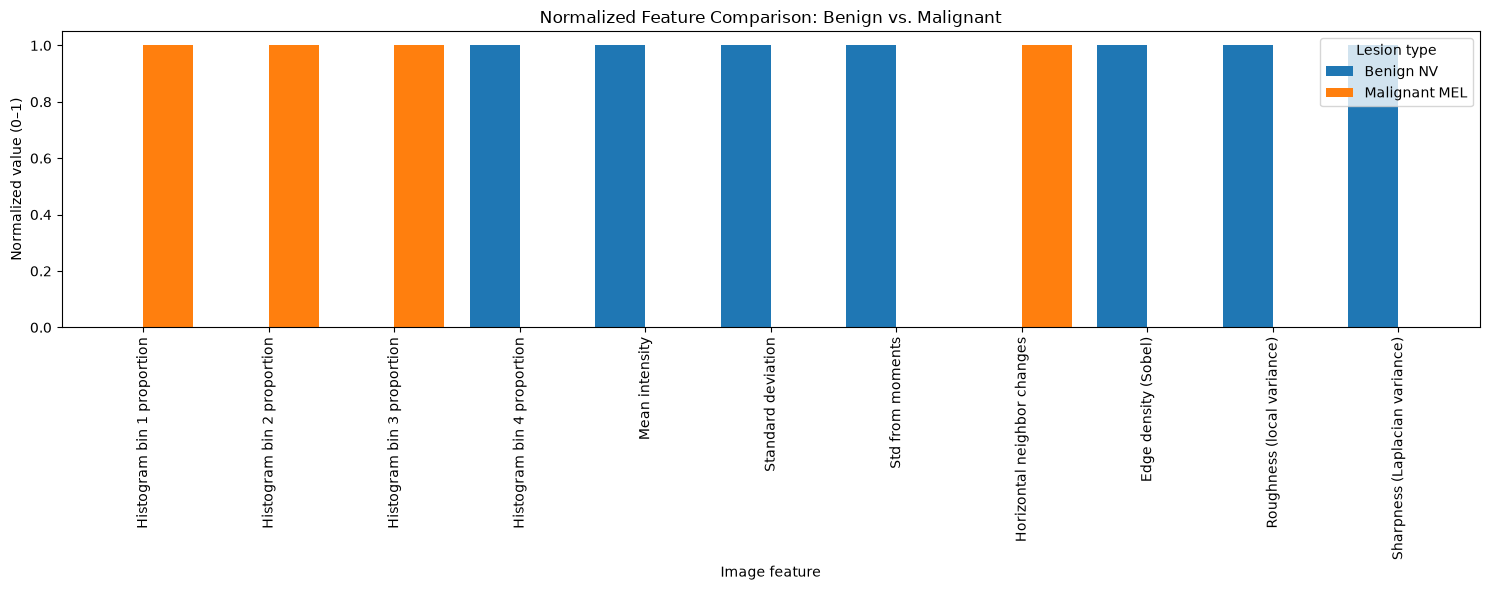

In [12]:
feature_ranges = feature_table.max(axis=1) - feature_table.min(axis=1)

scaled_feature_table = feature_table.copy()

for feature in feature_table.index:
    if feature_ranges[feature] != 0:
        scaled_feature_table.loc[feature] = (
            feature_table.loc[feature] - feature_table.loc[feature].min()
        ) / feature_ranges[feature]
    else:
        scaled_feature_table.loc[feature] = 0

scaled_feature_table.plot(
    kind="bar",
    figsize=(15, 6),
    width=0.8
)

plt.title("Normalized Feature Comparison: Benign vs. Malignant")
plt.ylabel("Normalized value (0–1)")
plt.xlabel("Image feature")
plt.xticks(rotation=90)
plt.legend(title="Lesion type")
plt.tight_layout()
plt.show()

In [13]:
comparison = feature_table.copy()

comparison["Difference (malignant - benign)"] = (
    comparison["Malignant MEL"] - comparison["Benign NV"]
)

display(comparison.round(4))

,Benign NV,Malignant MEL,Difference (malignant - benign)
Histogram bin 1 proportion,0.0203,0.0227,0.0024
Histogram bin 2 proportion,0.1805,0.2054,0.0250
Histogram bin 3 proportion,0.6503,0.7572,0.1069
Histogram bin 4 proportion,0.1489,0.0146,-0.1343
Mean intensity,158.3030,152.4044,-5.8987
Standard deviation,37.1552,32.7958,-4.3593
Std from moments,37.1552,32.7958,-4.3593
Horizontal neighbor changes,226839.0000,228433.0000,1594.0000
Edge density (Sobel),41.6547,25.6641,-15.9906
Roughness (local variance),150.0555,63.6515,-86.4041


In [14]:
benign_vector = np.array(list(benign_features.values()))
malignant_vector = np.array(list(malignant_features.values()))

print("BENIGN LESION FEATURE VECTOR")
print(benign_vector.round(4))
print("Length:", len(benign_vector))

print("\nMALIGNANT LESION FEATURE VECTOR")
print(malignant_vector.round(4))
print("Length:", len(malignant_vector))

BENIGN LESION FEATURE VECTOR
[     0.02       0.18       0.65       0.149    158.303     37.155
     37.155 226839.        41.655    150.055    861.38 ]
Length: 11

MALIGNANT LESION FEATURE VECTOR
[     0.023      0.205      0.757      0.015    152.404     32.796
     32.796 228433.        25.664     63.651     73.8  ]
Length: 11


In [15]:
output_dir = PROJECT_ROOT / "reports"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "image_features_comparison.csv"
feature_table.to_csv(output_path, index_label="Feature")

print("Saved feature table to:", output_path)

Saved feature table to: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\image_features_comparison.csv
